# Telco Müşteri Kaybı (Churn) Tahmini

**Problem:** Müşterinin aboneliğini iptal edip etmeyeceğini (`Churn`) tahmin etmek (ikili sınıflandırma).
**Metrikler:** F1 (ana), recall, ROC-AUC, accuracy (yardımcı).
**Veri:** Kaggle, Telco Customer Churn (7043 müşteri, 21 sütun).

## Adım 3: Veriyi yükleme ve ilk bakış

Veri analizi için `pandas` ve `numpy` kütüphanelerini çağırdık. Tüm sütunların görünmesi için görüntüleme ayarını açtık.

In [8]:
import pandas as pd
import numpy as np

CSV dosyasını `df` adlı tabloya (DataFrame) okuduk.


In [9]:
df= pd.read_csv("datatelco.csv")

Veri 7043 satır ve 21 sütundan oluşuyor. Hiçbir sütunda eksik değer görünmüyor, ancak `TotalCharges` sayı olması gerekirken metin (`object`) tipinde geldi. Bunu veri kalitesi adımında inceleyeceğiz.

In [10]:
print(df.shape)
print(df.info())

(7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null

Tablonun ilk ve son 5 satırına baktık. Sütunların çoğu `Yes/No` gibi metin değerleri içeriyor.

In [11]:
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [12]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


Hedef değişkenin dağılımına baktık: müşterilerin %73,5'i kalmış (No), %26,5'i ayrılmış (Yes). Sınıflar **dengesiz**, bu yüzden accuracy tek başına yeterli bir metrik olmayacak.

In [13]:
print(df['Churn'].value_counts())
print(df['Churn'].value_counts(normalize=True).round(4))

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.7346
Yes    0.2654
Name: proportion, dtype: float64


Sütun adlarını ve her sütundaki farklı değer sayısını inceledik. 2-4 değerli sütunlar kategorik, `tenure`, `MonthlyCharges` ve `TotalCharges` sayısal. `customerID` her satırda farklı olduğu için tahmine yardımcı olmayacak.

In [14]:
print(df.columns.tolist())
print(df.nunique())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64


## Adım 4: Veri kalitesi kontrolü

Eksik değer ve tekrarlayan satır kontrolü yaptık. Boş hücre yok, tekrarlayan satır veya müşteri numarası yok.

In [15]:
print(df.isnull().sum())
print(df.duplicated().sum())
print(df['customerID'].duplicated().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
0
0


`TotalCharges` sütununda metin olarak saklanan gizli eksikleri aradık. 11 satırda değer boşluk karakteri olarak yazılmış. Bu müşterilerin hepsinde `tenure = 0`, yani henüz ilk ayını doldurmamış yeni müşteriler. Toplam ödenen tutar gerçekten 0 olduğu için bunları 0 ile dolduracağız.

In [16]:
df[df['TotalCharges'] == ' ']


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [17]:
len(df[df['TotalCharges'] == ' '])


11

Tüm kategorik sütunlardaki farklı değerleri listeledik. Yazım tutarsızlığı yok. `No phone service` ve `No internet service` değerleri başka sütunlardaki bilgiyi tekrar ediyor. `SeniorCitizen` 0/1, diğerleri Yes/No yazıyor.

In [18]:
for sutun in ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']:
    print(sutun, df[sutun].unique())





gender ['Female' 'Male']
Partner ['Yes' 'No']
Dependents ['No' 'Yes']
PhoneService ['No' 'Yes']
MultipleLines ['No phone service' 'No' 'Yes']
InternetService ['DSL' 'Fiber optic' 'No']
OnlineSecurity ['No' 'Yes' 'No internet service']
OnlineBackup ['Yes' 'No' 'No internet service']
DeviceProtection ['No' 'Yes' 'No internet service']
TechSupport ['No' 'Yes' 'No internet service']
StreamingTV ['No' 'Yes' 'No internet service']
StreamingMovies ['No' 'Yes' 'No internet service']
Contract ['Month-to-month' 'One year' 'Two year']
PaperlessBilling ['Yes' 'No']
PaymentMethod ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
Churn ['No' 'Yes']


Sayısal sütunların özetine baktık. `tenure` 0-72, `MonthlyCharges` 18,25-118,75 arasında, mantıksız değer yok. `TotalCharges` metin olduğu için tabloda görünmedi.

In [19]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


## Adım 5: Keşifsel Veri Analizi (EDA)

Analiz için `df`'in kopyasını (`eda`) aldık, `TotalCharges` boşluklarını 0 yapıp sayıya çevirdik. Asıl veriyi temizleme adımında düzenleyeceğiz.

In [20]:
eda = df.copy()
eda['TotalCharges'] = eda['TotalCharges'].replace(" ","0")
eda['TotalCharges'] = eda['TotalCharges'].astype(float)

Float a çevirme olmuş mu diye describe çalıştırıyouz ve TotalCharges sütununun min max değerlerini kontol ediyoruz

In [21]:
eda.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


Ayrılan ve kalan müşterilerin sayısal sütun ortalamalarını karşılaştırdık. Ayrılanlar ortalama 18 aydır müşteri (kalanlarda 37,6 ay) ve daha yüksek aylık ücret ödüyor (74,4 ve 61,3).

In [22]:
eda.groupby('Churn')[['tenure', 'MonthlyCharges', 'TotalCharges']].mean()

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.569965,61.265124,2549.911442
Yes,17.979133,74.441332,1531.796094


Kategorik sütunlarda churn oranlarına baktık:
- `Contract`: aylık %42,7, bir yıllık %11,3, iki yıllık %2,8
- `InternetService`: fiber optik %41,9, DSL %19, internetsiz %7,4
- `PaymentMethod`: electronic check %45,3, diğerleri %15-19
- `gender`: kadın %26,9, erkek %26,2, fark yok

In [23]:
pd.crosstab(eda['Contract'], eda['Churn'], normalize='index').round(3)

Churn,No,Yes
Contract,,
Month-to-month,0.573,0.427
One year,0.887,0.113
Two year,0.972,0.028


In [24]:
pd.crosstab(eda['InternetService'], eda['Churn'], normalize='index').round(3)

Churn,No,Yes
InternetService,,
DSL,0.810,0.190
Fiber optic,0.581,0.419
No,0.926,0.074


In [25]:
pd.crosstab(eda['PaymentMethod'], eda['Churn'], normalize='index').round(3)

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),0.833,0.167
Credit card (automatic),0.848,0.152
Electronic check,0.547,0.453
Mailed check,0.809,0.191


In [26]:
pd.crosstab(eda['gender'], eda['Churn'], normalize='index').round(3)

Churn,No,Yes
gender,,
Female,0.731,0.269
Male,0.738,0.262


Grafik çizmek için `matplotlib` ve `seaborn` kütüphanelerini çağırdık.

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

Hedef değişkenin çubuk grafiğini çizdik. "No" sınıfı "Yes"in yaklaşık 3 katı, dengesizlik görsel olarak da görünüyor.

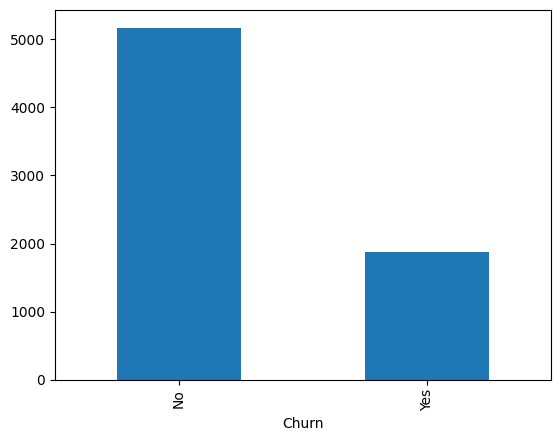

In [28]:
eda['Churn'].value_counts().plot(kind='bar')
plt.show()

`tenure`, `MonthlyCharges` ve `TotalCharges` dağılımlarını çizdik. `tenure` baş ve sonda yığılıyor, `TotalCharges` sola yığılmış ve sağ kuyruklu.

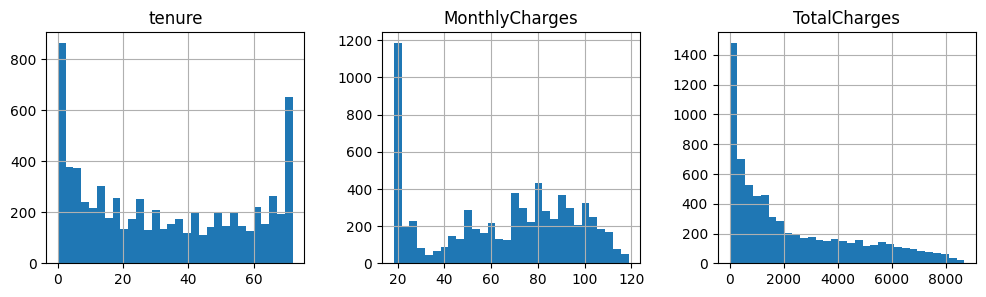

In [29]:
eda[['tenure', 'MonthlyCharges', 'TotalCharges']].hist(bins=30, figsize=(12, 3), layout=(1, 3))
plt.show()

Üç sayısal sütunu churn durumuna göre boxplot ile karşılaştırdık. Ciddi bir aykırı değer sorunu yok, uzak noktalar gerçek müşteri davranışı olabilir, bu yüzden silmedik.

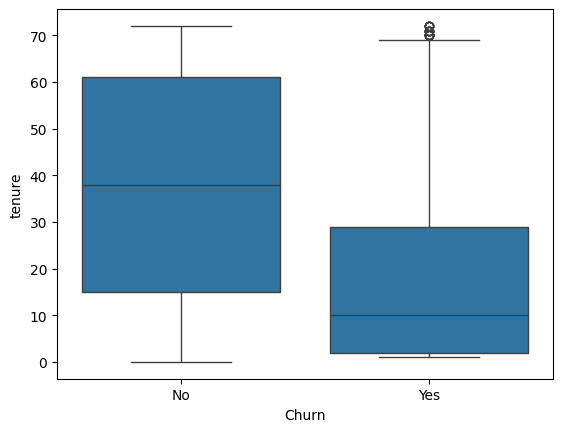

In [30]:
sns.boxplot(x='Churn', y='tenure', data=eda)
plt.show()

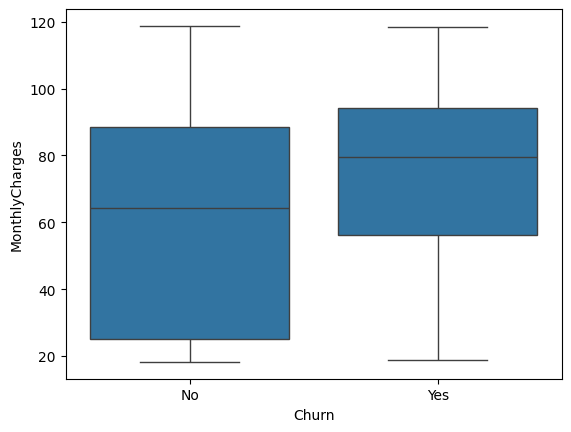

In [31]:
sns.boxplot(x='Churn', y='MonthlyCharges', data=eda)
plt.show()

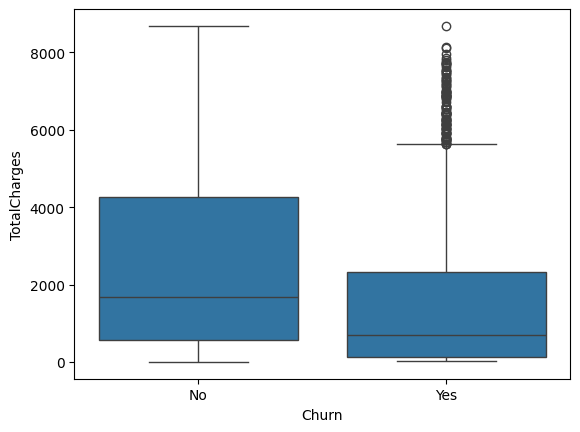

In [32]:
sns.boxplot(x='Churn', y='TotalCharges', data=eda)
plt.show()

Sayısal sütunlar ile churn arasındaki korelasyonu ısı haritasıyla gösterdik. `tenure` ile churn arasında negatif ilişki var (süre arttıkça ayrılma azalıyor). `tenure` ile `TotalCharges` birbirine çok bağlı.

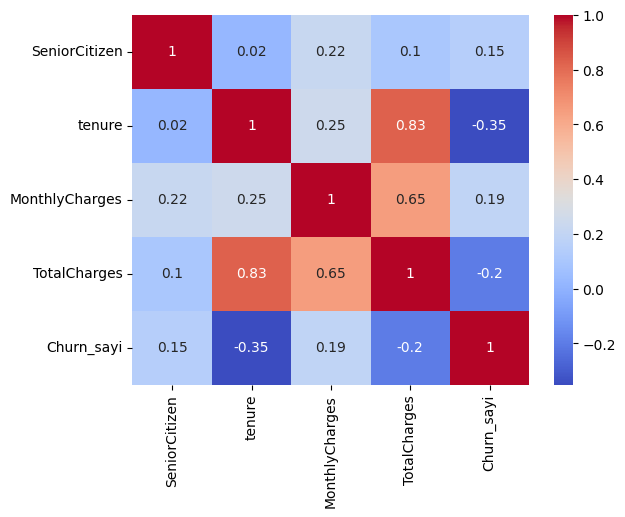

In [33]:
eda_sayi = eda[['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']].copy()
eda_sayi['Churn_sayi'] = (eda['Churn'] == 'Yes').astype(int)
sns.heatmap(eda_sayi.corr().round(2), annot=True, cmap='coolwarm')
plt.show()

`TechSupport`, `OnlineSecurity`, `SeniorCitizen`, `Partner` ve `PaperlessBilling` sütunlarının churn oranlarına baktık.

In [34]:
pd.crosstab(eda['TechSupport'], eda['Churn'], normalize='index').round(3)

Churn,No,Yes
TechSupport,,
No,0.584,0.416
No internet service,0.926,0.074
Yes,0.848,0.152


In [35]:
pd.crosstab(eda['OnlineSecurity'], eda['Churn'], normalize='index').round(3)

Churn,No,Yes
OnlineSecurity,,
No,0.582,0.418
No internet service,0.926,0.074
Yes,0.854,0.146


In [36]:
pd.crosstab(eda['SeniorCitizen'], eda['Churn'], normalize='index').round(3)

Churn,No,Yes
SeniorCitizen,,
0,0.764,0.236
1,0.583,0.417


In [37]:
pd.crosstab(eda['Partner'], eda['Churn'], normalize='index').round(3)

Churn,No,Yes
Partner,,
No,0.670,0.330
Yes,0.803,0.197


In [38]:
pd.crosstab(eda['PaperlessBilling'], eda['Churn'], normalize='index').round(3)

Churn,No,Yes
PaperlessBilling,,
No,0.837,0.163
Yes,0.664,0.336


### EDA bulguları
1. Sözleşme türü en güçlü sinyal (aylık %42,7, iki yıllık %2,8).
2. Ayrılanlar daha kısa süredir müşteri.
3. Fiber optik müşterilerde churn yüksek (%41,9).
4. Electronic check kullananlarda churn yüksek (%45,3).
5. Cinsiyet churn'ü etkilemiyor, modelden çıkaracağız.

## Adım 6: Veri temizleme ve ön işleme

Temizlik kararlarını uyguladık:
- `TotalCharges` boşluklarını 0 yaptık ve sayıya çevirdik.
- `customerID` (her satırda farklı) ve `gender` (EDA'da etkisiz) sütunlarını çıkardık.
- Hedef sütunu `Churn`'ü Yes → 1, No → 0 yaptık.

Ölçekleme burada yapılmadı, veri bölündükten sonra yapılacak (data leakage'dan kaçınmak için).

In [39]:
df_clean = df.copy()

# 1) TotalCharges: boşlukları 0 yap, sayıya çevir
df_clean['TotalCharges'] = df_clean['TotalCharges'].replace(' ', '0').astype(float)

# 2) Gereksiz sütunları çıkar
df_clean = df_clean.drop(columns=['customerID', 'gender'])

# 3) Hedef sütunu: Yes -> 1, No -> 0
df_clean['Churn'] = df_clean['Churn'].replace({'Yes': 1, 'No': 0}).astype(int)

/tmp/ipykernel_3502/3054341086.py:10: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_clean['Churn'] = df_clean['Churn'].replace({'Yes': 1, 'No': 0}).astype(int)


Yes/No değerli sütunları 0/1'e çevirdik. `No phone service` ve `No internet service` değerleri başka sütunlarda zaten bilindiği için 0 yapıldı.

In [40]:
evet_hayir = ['Partner', 'Dependents', 'PhoneService', 'MultipleLines',
              'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
              'StreamingTV', 'StreamingMovies', 'PaperlessBilling']

df_clean[evet_hayir] = df_clean[evet_hayir].replace(
    {'Yes': 1, 'No': 0, 'No phone service': 0, 'No internet service': 0}
).astype(int)

/tmp/ipykernel_3502/839351839.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_clean[evet_hayir] = df_clean[evet_hayir].replace(


Veri tiplerini kontrol ettik. `InternetService`, `Contract` ve `PaymentMethod` dışında metin sütun kalmadı. Bu üçü bir sonraki adımda one-hot encoding ile sayıya çevrilecek.

In [41]:
df_clean.dtypes

,0
SeniorCitizen,int64
Partner,int64
Dependents,int64
tenure,int64
PhoneService,int64
MultipleLines,int64
InternetService,object
OnlineSecurity,int64
OnlineBackup,int64
DeviceProtection,int64


## Adım 7: Feature engineering

İki yeni özellik türettik:
- `service_count`: müşterinin aldığı ek hizmet sayısı (0-6)
- `tenure_group`: müşterilik süresini 4 gruba böldük (0-12, 13-24, 25-48, 49-72 ay)

In [42]:
ek_hizmetler = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                'TechSupport', 'StreamingTV', 'StreamingMovies']

df_clean['service_count'] = df_clean[ek_hizmetler].sum(axis=1)

df_clean['tenure_group'] = pd.cut(df_clean['tenure'],
                                  bins=[-1, 12, 24, 48, 72],
                                  labels=['0-12', '13-24', '25-48', '49-72']).astype(str)

Kalan metin sütunlarını (`InternetService`, `Contract`, `PaymentMethod`, `tenure_group`) one-hot encoding ile 0/1 sütunlara çevirdik. `drop_first=True` ile gereksiz tekrarı önledik. Sonuç: 27 sütun (26 özellik + 1 hedef), hepsi sayısal.

Hedef bilgisini sızdıran bir sütun olmadığını (data leakage) kontrol ettik.

In [43]:
df_model = pd.get_dummies(df_clean,
                          columns=['InternetService', 'Contract', 'PaymentMethod', 'tenure_group'],
                          drop_first=True, dtype=int)
df_model.shape

(7043, 27)

In [44]:
df_model.head()

,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,...,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,tenure_group_13-24,tenure_group_25-48,tenure_group_49-72
0,0,1,0,1,0,0,0,1,0,0,...,0,0,0,0,0,1,0,0,0,0
1,0,0,0,34,1,0,1,0,1,0,...,0,0,1,0,0,0,1,0,1,0
2,0,0,0,2,1,0,1,1,0,0,...,0,0,0,0,0,0,1,0,0,0
3,0,0,0,45,0,0,1,0,1,1,...,0,0,1,0,0,0,0,0,1,0
4,0,0,0,2,1,0,0,0,0,0,...,1,0,0,0,0,1,0,0,0,0


In [45]:
df_model.columns.tolist()


['SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'PaperlessBilling',
 'MonthlyCharges',
 'TotalCharges',
 'Churn',
 'service_count',
 'InternetService_Fiber optic',
 'InternetService_No',
 'Contract_One year',
 'Contract_Two year',
 'PaymentMethod_Credit card (automatic)',
 'PaymentMethod_Electronic check',
 'PaymentMethod_Mailed check',
 'tenure_group_13-24',
 'tenure_group_25-48',
 'tenure_group_49-72']

In [46]:
df_model.dtypes.value_counts()

,count
int64,25
float64,2


## Adım 8: Veriyi bölme

Veriyi özellikler (`X`) ve hedef (`y`) olarak ayırdık, sonra %70 train / %15 validation / %15 test olarak böldük (4930 / 1056 / 1057 satır). `stratify` ile her parçada churn oranını yaklaşık %26,5 tuttuk, `random_state=42` ile bölmeyi sabitledik. Test setine Adım 12'ye kadar dokunmuyoruz.

In [47]:
from sklearn.model_selection import train_test_split

X = df_model.drop(columns=['Churn'])
y = df_model['Churn']

print(X.shape, y.shape)


(7043, 26) (7043,)


In [48]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

print(X_train.shape, X_val.shape, X_test.shape)
print(y_train.mean().round(3), y_val.mean().round(3), y_test.mean().round(3))

(4930, 26) (1056, 26) (1057, 26)
0.265 0.265 0.266


Sayısal sütunları (`tenure`, `MonthlyCharges`, `TotalCharges`, `service_count`) ölçekledik. Ölçekleyici **sadece train verisinde** öğrenildi (`fit`), validation ve test'e sadece uygulandı (`transform`), böylece veri sızıntısı olmadı. Ölçekli kopyalar lojistik regresyon için, ham veri ağaç modelleri için kullanılacak.

In [49]:
from sklearn.preprocessing import StandardScaler
sayisal = ['tenure', 'MonthlyCharges', 'TotalCharges', 'service_count']


scaler = StandardScaler()

X_train_s = X_train.copy()
X_val_s = X_val.copy()
X_test_s = X_test.copy()

X_train_s[sayisal] = scaler.fit_transform(X_train[sayisal])
X_val_s[sayisal] = scaler.transform(X_val[sayisal])
X_test_s[sayisal] = scaler.transform(X_test[sayisal])



In [50]:
print(X_train_s[sayisal].mean().round(2))
print(X_train_s[sayisal].std().round(2))

tenure            0.0
MonthlyCharges    0.0
TotalCharges     -0.0
service_count    -0.0
dtype: float64
tenure            1.0
MonthlyCharges    1.0
TotalCharges      1.0
service_count     1.0
dtype: float64


In [51]:
print(X_val_s[sayisal].mean().round(2))

tenure           -0.03
MonthlyCharges    0.02
TotalCharges     -0.04
service_count    -0.03
dtype: float64


In [52]:
X_train[sayisal].head(3)

,tenure,MonthlyCharges,TotalCharges,service_count
5557,5,80.20,384.25,1
2270,3,86.85,220.95,2
6930,3,75.15,216.75,0


## Adım 9: Baseline model

Modelleri aynı şekilde değerlendirmek için bir fonksiyon yazdık. Accuracy, F1, recall ve ROC-AUC değerlerini yazdırıyor.

In [53]:
from sklearn.metrics import accuracy_score, f1_score, recall_score, roc_auc_score

def degerlendir(model, X, y):
    tahmin = model.predict(X)
    olasilik = model.predict_proba(X)[:, 1]
    print("Accuracy:", round(accuracy_score(y, tahmin), 3))
    print("F1 (churn):", round(f1_score(y, tahmin, zero_division=0), 3))
    print("Recall (churn):", round(recall_score(y, tahmin), 3))
    print("ROC-AUC:", round(roc_auc_score(y, olasilik), 3))

İki baseline model eğittik ve validation'da değerlendirdik:
- **Hep "ayrılmaz" diyen model:** accuracy 0.735 ama F1 ve recall 0. Accuracy yanıltıcı, bu model hiçbir ayrılanı yakalamıyor.
- **Basit lojistik regresyon:** accuracy 0.809, F1 0.610, recall 0.564, ROC-AUC 0.847. Sonraki modellerin geçmesi gereken referans.

In [54]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
print("--- Hep 'ayrılmaz' diyen model ---")
degerlendir(dummy, X_val, y_val)

lr_basit = LogisticRegression(max_iter=1000)
lr_basit.fit(X_train_s, y_train)
print("--- Basit Lojistik Regresyon ---")
degerlendir(lr_basit, X_val_s, y_val)

--- Hep 'ayrılmaz' diyen model ---
Accuracy: 0.735
F1 (churn): 0.0
Recall (churn): 0.0
ROC-AUC: 0.5
--- Basit Lojistik Regresyon ---
Accuracy: 0.809
F1 (churn): 0.61
Recall (churn): 0.564
ROC-AUC: 0.847


## Adım 10: Model eğitimi ve karşılaştırma

Üç modeli `class_weight='balanced'` ile 5 parçalı cross-validation'da F1'e göre karşılaştırdık: Lojistik Regresyon (0.626), Random Forest (0.543), Gradient Boosting (0.618).

In [55]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier # 2 model türünü import ettik
from sklearn.model_selection import StratifiedKFold, cross_val_score # veriyi bölme aracını çağırdık

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) # dataseti bölme kuralları: (n_split = 5)veri 5 parçaya bölenecek, (shuffle= true)bölmeden önce satırlar karşılaştıtılacak, (random_state=42)karıştırmayı her çalıştırıdğında aynı sayıyı versin diye sabit

# her model için model nesnesi oluşturduk
lr = LogisticRegression(max_iter=1000, class_weight='balanced') #log. reg. öğrenirken max 100 kere çalışsın ve sınıf ağırlıklarını eşitledik
rf = RandomForestClassifier(random_state=42, class_weight='balanced') #modelin içimdeki rastegele işlmler hep aynı olsun : 42
hgb = HistGradientBoostingClassifier(random_state=42, class_weight='balanced')


print("Lojistik Regresyon CV F1:", cross_val_score(lr, X_train_s, y_train, cv=cv, scoring='f1').mean().round(3)) # Bu fonksiyon veriyi 5 parçaya böler, 4 parçayla modeli eğitir, kalan 1 parçada F1 hesaplar ve bunu 5 kez tekrarlar. Sonuç 5 sayıdır.
print("Random Forest CV F1:", cross_val_score(rf, X_train, y_train, cv=cv, scoring='f1').mean().round(3))
print("Gradient Boosting CV F1:", cross_val_score(hgb, X_train, y_train, cv=cv, scoring='f1').mean().round(3))

Lojistik Regresyon CV F1: 0.626
Random Forest CV F1: 0.543
Gradient Boosting CV F1: 0.618


Train ve validation F1 skorlarını kıyasladık. Lojistik regresyonda fark yok (0.629 / 0.626). Random Forest ağır overfit etmiş (0.995 / 0.545). Gradient Boosting'de orta düzey overfitting var (0.796 / 0.611).

In [56]:
lr.fit(X_train_s, y_train)
rf.fit(X_train, y_train)
hgb.fit(X_train, y_train)

print("LR   train F1:", round(f1_score(y_train, lr.predict(X_train_s)), 3), "| val F1:", round(f1_score(y_val, lr.predict(X_val_s)), 3))
print("RF   train F1:", round(f1_score(y_train, rf.predict(X_train)), 3), "| val F1:", round(f1_score(y_val, rf.predict(X_val)), 3))
print("HGB  train F1:", round(f1_score(y_train, hgb.predict(X_train)), 3), "| val F1:", round(f1_score(y_val, hgb.predict(X_val)), 3))

LR   train F1: 0.629 | val F1: 0.626
RF   train F1: 0.995 | val F1: 0.545
HGB  train F1: 0.796 | val F1: 0.611


Üç modeli validation'da tüm metriklerle karşılaştırdık. `balanced` ayarı recall'u 0.564'ten 0.825'e çıkardı, bunun bedeli accuracy'nin düşmesi (daha çok yanlış alarm). Random Forest her metrikte geride kaldığı için elendi. Lojistik Regresyon ve Gradient Boosting ayara alındı.

In [57]:
print("--- Lojistik Regresyon ---"); degerlendir(lr, X_val_s, y_val)
print("--- Random Forest ---"); degerlendir(rf, X_val, y_val)
print("--- Gradient Boosting ---"); degerlendir(hgb, X_val, y_val)

--- Lojistik Regresyon ---
Accuracy: 0.739
F1 (churn): 0.626
Recall (churn): 0.825
ROC-AUC: 0.847
--- Random Forest ---
Accuracy: 0.783
F1 (churn): 0.545
Recall (churn): 0.489
ROC-AUC: 0.822
--- Gradient Boosting ---
Accuracy: 0.753
F1 (churn): 0.611
Recall (churn): 0.732
ROC-AUC: 0.833


## Adım 11: Hiperparametre ayarı

Lojistik regresyonun `C` değerini Grid Search ile ayarladık (sadece train'de, CV ile). En iyi `C = 0.01`, CV F1 0.631.

In [58]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

arama_lr = GridSearchCV(LogisticRegression(max_iter=1000, class_weight='balanced'),
                        param_grid={'C': [0.01, 0.1, 1, 10]},
                        cv=cv, scoring='f1')
arama_lr.fit(X_train_s, y_train)
print("En iyi ayar:", arama_lr.best_params_)
print("CV F1:", round(arama_lr.best_score_, 3))

En iyi ayar: {'C': 0.01}
CV F1: 0.631


Gradient Boosting'in ayarlarını (`learning_rate`, `max_depth`, `max_leaf_nodes`, `min_samples_leaf`) Random Search ile 15 kombinasyon deneyerek ayarladık. En iyi ayar: `learning_rate=0.03`, `max_leaf_nodes=15`, `min_samples_leaf=50`, `max_depth=None`. CV F1 0.618'den 0.631'e çıktı.

In [59]:
param_hgb = {'learning_rate': [0.03, 0.05, 0.1],
             'max_depth': [3, 5, None],
             'max_leaf_nodes': [15, 31],
             'min_samples_leaf': [20, 50, 100]}

arama_hgb = RandomizedSearchCV(HistGradientBoostingClassifier(random_state=42, class_weight='balanced'),
                               param_distributions=param_hgb, n_iter=15,
                               cv=cv, scoring='f1', random_state=42, n_jobs=-1)
arama_hgb.fit(X_train, y_train)
print("En iyi ayar:", arama_hgb.best_params_)
print("CV F1:", round(arama_hgb.best_score_, 3))

En iyi ayar: {'min_samples_leaf': 50, 'max_leaf_nodes': 15, 'max_depth': None, 'learning_rate': 0.03}
CV F1: 0.631


Ayarlı iki modeli validation'da karşılaştırdık. Gradient Boosting dört metriğin dördünde önde (F1 0.647, recall 0.839, ROC-AUC 0.847). **Final model olarak Gradient Boosting'i seçtik.**

In [60]:
print("--- Ayarlı Lojistik Regresyon ---")
degerlendir(arama_lr.best_estimator_, X_val_s, y_val)
print("--- Ayarlı Gradient Boosting ---")
degerlendir(arama_hgb.best_estimator_, X_val, y_val)

--- Ayarlı Lojistik Regresyon ---
Accuracy: 0.74
F1 (churn): 0.618
Recall (churn): 0.793
ROC-AUC: 0.842
--- Ayarlı Gradient Boosting ---
Accuracy: 0.758
F1 (churn): 0.647
Recall (churn): 0.839
ROC-AUC: 0.847


Ayarlı Gradient Boosting'in train skorunu kontrol ettik (F1 0.656, validation 0.647). Ayarsız modeldeki ezberleme (0.796 / 0.611) neredeyse ortadan kalktı.

In [61]:
degerlendir(arama_hgb.best_estimator_, X_train, y_train)

Accuracy: 0.772
F1 (churn): 0.656
Recall (churn): 0.817
ROC-AUC: 0.875


## Adım 12: Final değerlendirme

Final modeli test setinde **bir kez** değerlendirdik: accuracy 0.763, F1 0.635, recall 0.776, ROC-AUC 0.842. F1 ve ROC-AUC validation'a çok yakın, model yeni müşterilerde de benzer çalışıyor. Recall validation'da 0.839, test'te 0.776 çıktı.

In [62]:
en_iyi_model = arama_hgb.best_estimator_
degerlendir(en_iyi_model, X_test, y_test)

Accuracy: 0.763
F1 (churn): 0.635
Recall (churn): 0.776
ROC-AUC: 0.842


Sınıf bazlı rapor ve confusion matrix çıkardık. Ayrılan 281 müşterinin 218'ini yakaladık, 63'ünü kaçırdık. Yaklaşık 188 müşteriye de yanlış alarm verdik.

              precision    recall  f1-score   support

       Kaldı       0.90      0.76      0.82       776
     Ayrıldı       0.54      0.78      0.63       281

    accuracy                           0.76      1057
   macro avg       0.72      0.77      0.73      1057
weighted avg       0.81      0.76      0.77      1057



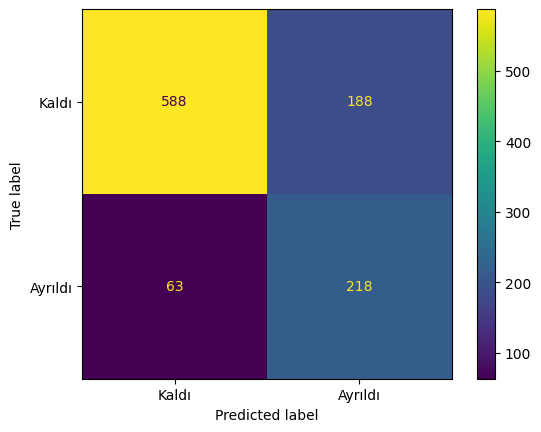

In [63]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

tahmin = en_iyi_model.predict(X_test)
print(classification_report(y_test, tahmin, target_names=['Kaldı', 'Ayrıldı']))
ConfusionMatrixDisplay.from_predictions(y_test, tahmin, display_labels=['Kaldı', 'Ayrıldı'])
plt.show()

Modelin kaçırdığı ve yakaladığı ayrılan müşterileri karşılaştırdık. Yakalananlar yeni müşteri (ortalama 13 ay), pahalı paket (74), az ek hizmet (1,5). Kaçırılanlar uzun süreli (31 ay), daha ucuz paket (61,7), daha çok hizmet alan (2,1) müşteriler. Model uzun süreli müşterilerin ayrılmasını yakalamakta zayıf.

In [64]:
kacirilan = X_test[(y_test == 1) & (tahmin == 0)]
yakalanan = X_test[(y_test == 1) & (tahmin == 1)]

print("Kaçırılan:", len(kacirilan), "| Yakalanan:", len(yakalanan))
print("--- Kaçırılanların ortalaması ---")
print(kacirilan[['tenure', 'MonthlyCharges', 'service_count']].mean().round(1))
print("--- Yakalananların ortalaması ---")
print(yakalanan[['tenure', 'MonthlyCharges', 'service_count']].mean().round(1))

Kaçırılan: 63 | Yakalanan: 218
--- Kaçırılanların ortalaması ---
tenure            31.0
MonthlyCharges    61.7
service_count      2.1
dtype: float64
--- Yakalananların ortalaması ---
tenure            13.2
MonthlyCharges    74.0
service_count      1.5
dtype: float64


## Adım 13: Yorumlama

Permutation importance ile modelin hangi özelliklere baktığını ölçtük (validation üzerinde). En önemli özellikler: `Contract_Two year` (0.088), `Contract_One year` (0.051), `tenure` (0.050), `InternetService_Fiber optic` (0.041). Bu sonuçlar EDA bulgularımızla tutarlı.

In [65]:
from sklearn.inspection import permutation_importance

sonuc = permutation_importance(en_iyi_model, X_val, y_val,
                               scoring='f1', n_repeats=10, random_state=42)
onem = pd.Series(sonuc.importances_mean, index=X_val.columns).sort_values(ascending=False)
onem.head(10)

,0
Contract_Two year,0.088319
Contract_One year,0.050767
tenure,0.049781
InternetService_Fiber optic,0.040628
InternetService_No,0.014462
MonthlyCharges,0.011374
TotalCharges,0.008420
PaymentMethod_Electronic check,0.007096
Dependents,0.003436
OnlineSecurity,0.003176


İlk 10 özelliğin önemini grafikle gösterdik. `service_count` ve `tenure_group` ilk 10'da yok, yani feature engineering ile eklediğimiz sütunlar belirgin katkı sağlamadı.

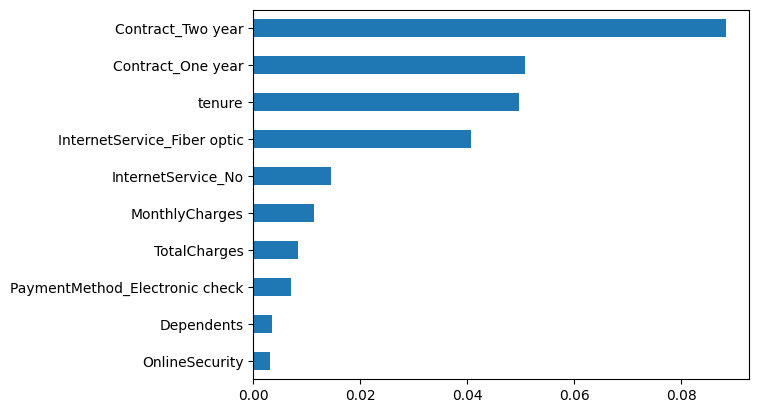

In [66]:
onem.head(10).sort_values().plot(kind='barh')
plt.show()

## Adım 14: Kaydetme

Final modeli ve sütun listesini dosyaya kaydettik. Kütüphane versiyonlarını not ettik (tekrar üretilebilirlik). Final model ağaç tabanlı ve ham veriyle çalıştığı için ölçekleyiciyi kaydetmedik.

In [67]:
import joblib
import sklearn

joblib.dump(en_iyi_model, 'churn_model.joblib')
joblib.dump(list(X_train.columns), 'sutunlar.joblib')

print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__)
print("numpy:", np.__version__)

scikit-learn: 1.6.1
pandas: 2.2.3
numpy: 2.1.3


Kaydedilen modeli geri yükleyip orijinalle aynı tahminleri verdiğini doğruladık (`True`).

In [68]:
model_geri = joblib.load('churn_model.joblib')
print((model_geri.predict(X_test) == en_iyi_model.predict(X_test)).all())

True


Model ve sütun listesini bilgisayara indirdik.

In [69]:
from google.colab import files
files.download('churn_model.joblib')
files.download('sutunlar.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [70]:
def musteri_satiri(sozlesme, tenure, internet, odeme, aylik_ucret, ek_hizmet):
    # 26 sütunun hepsi 0 olan boş bir satır (sütun sırası eğitimdekiyle aynı)
    satir = pd.DataFrame(0, index=[0], columns=X_train.columns)

    satir['PhoneService'] = 1            # varsayım: herkesin telefon hizmeti var
    satir['tenure'] = tenure
    satir['MonthlyCharges'] = aylik_ucret
    satir['TotalCharges'] = tenure * aylik_ucret   # yaklaşık toplam ödeme

    if sozlesme == '1 yıllık':
        satir['Contract_One year'] = 1
    elif sozlesme == '2 yıllık':
        satir['Contract_Two year'] = 1
    # 'Aylık' ise ikisi de 0 kalır

    if internet == 'Fiber':
        satir['InternetService_Fiber optic'] = 1
    elif internet == 'Yok':
        satir['InternetService_No'] = 1
        ek_hizmet = 0                    # internet yoksa ek hizmet de yok
    # 'DSL' ise ikisi de 0 kalır

    if odeme == 'Electronic check':
        satir['PaymentMethod_Electronic check'] = 1
    elif odeme == 'Mailed check':
        satir['PaymentMethod_Mailed check'] = 1
    elif odeme == 'Kredi kartı':
        satir['PaymentMethod_Credit card (automatic)'] = 1
    # 'Banka havalesi' ise hepsi 0 kalır

    if 12 < tenure <= 24:
        satir['tenure_group_13-24'] = 1
    elif 24 < tenure <= 48:
        satir['tenure_group_25-48'] = 1
    elif tenure > 48:
        satir['tenure_group_49-72'] = 1

    for hizmet in ek_hizmetler[:ek_hizmet]:   # ilk N ek hizmeti 1 yap
        satir[hizmet] = 1
    satir['service_count'] = ek_hizmet

    return satir




In [71]:
def tahmin_et(sozlesme, tenure, internet, odeme, aylik_ucret, ek_hizmet):
    satir = musteri_satiri(sozlesme, tenure, internet, odeme, aylik_ucret, ek_hizmet)
    olasilik = en_iyi_model.predict_proba(satir)[0, 1]
    karar = en_iyi_model.predict(satir)[0]

    if karar == 1:
        return (f"⚠️ Bu müşterinin ayrılma olasılığı %{olasilik*100:.0f}. "
                f"Risk yüksek: elde tutma kampanyası sunulabilir.")
    else:
        return (f"✅ Bu müşterinin ayrılma olasılığı %{olasilik*100:.0f}. "
                f"Risk düşük: şu an için özel bir işlem gerekmiyor.")

In [72]:
print("--- Müşteri Kaybı Tahmin Aracı ---")
sozlesme = input("Sözleşme türü (Aylık / 1 yıllık / 2 yıllık): ")
tenure = int(input("Kaç aydır müşteri (0-72): "))
internet = input("İnternet türü (DSL / Fiber / Yok): ")
odeme = input("Ödeme yöntemi (Electronic check / Mailed check / Kredi kartı / Banka havalesi): ")
aylik_ucret = float(input("Aylık ücret (örn. 70.5): "))
ek_hizmet = int(input("Ek hizmet sayısı (0-6): "))

print(tahmin_et(sozlesme, tenure, internet, odeme, aylik_ucret, ek_hizmet))

--- Müşteri Kaybı Tahmin Aracı ---
Sözleşme türü (Aylık / 1 yıllık / 2 yıllık): 1 yıllık
Kaç aydır müşteri (0-72): 61
İnternet türü (DSL / Fiber / Yok): fiber
Ödeme yöntemi (Electronic check / Mailed check / Kredi kartı / Banka havalesi): kredi kartı
Aylık ücret (örn. 70.5): 200.0
Ek hizmet sayısı (0-6): 4
✅ Bu müşterinin ayrılma olasılığı %16. Risk düşük: şu an için özel bir işlem gerekmiyor.
